<a href="https://colab.research.google.com/github/AngelaB08/Project-1_Fruit-Prices-2023/blob/main/Project_1_Fruit_Prices_2023_Angela_Boniila.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 1_Fruit Prices 2023
Name: Angela Bonilla

Dataset Research Focus Question: How does the form of fruit affect its cost, and which fruit products offer the lowest cost per cup equivalent?

In [39]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
url = "https://raw.githubusercontent.com/AngelaB08/Fruits-and-Vegetables/refs/heads/main/fruit-prices-2023.csv"
df = pd.read_csv(url)

# Display the first five rows
df.head()

,Fruit,Form,AverageRetailPrice,AverageRetailPriceUnitOfMeasure,PreparationYieldFactor,SizeOfACupEquivalent,CupEquivalentUnitOfMeasure,AveragePricePerCupEquivalent
0,Apples,Fresh,1.860931,per pound,0.90,0.2425,pounds,0.501435
1,"Apples, applesauce",Canned,1.208099,per pound,1.00,0.5401,pounds,0.652534
2,"Apples, ready to drink",Juice,0.951115,per pint (16 fluid ounces ready to drink),1.00,0.5000,pints,0.475558
3,"Apples, frozen concentrate",Juice,2.668334,per pint (16 fluid ounces concentrate),4.00,0.5000,pints,0.333542
4,Apricots,Fresh,3.803732,per pound,0.93,0.3638,pounds,1.487802


In [40]:

# Find the number of rows and columns
print("Dataset dimensions:", df.shape)

# Display all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and non-missing values
print("\nDataset information:")
df.info()


Dataset dimensions: (62, 8)

Column names:
['Fruit', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Fruit                            62 non-null     object 
 1   Form                             62 non-null     object 
 2   AverageRetailPrice               62 non-null     float64
 3   AverageRetailPriceUnitOfMeasure  62 non-null     object 
 4   PreparationYieldFactor           62 non-null     float64
 5   SizeOfACupEquivalent             62 non-null     float64
 6   CupEquivalentUnitOfMeasure       62 non-null     object 
 7   AveragePricePerCupEquivalent     62 non-null     float64
dtypes: float64(4), objec

As it can be observes, there are no missing values within my data. Along with this discovery, we can also observe the overall summary statistic for each row of data.

In [41]:

# Count missing values in each column
print("Missing values by column:")
print(df.isnull().sum())

# Count completely duplicated rows
print("\nNumber of duplicate rows:")
print(df.duplicated().sum())

# Calculate the percentage of missing values
print("\nMissing value percentages:")
print((df.isnull().mean() * 100).round(2))


Missing values by column:
Fruit                              0
Form                               0
AverageRetailPrice                 0
AverageRetailPriceUnitOfMeasure    0
PreparationYieldFactor             0
SizeOfACupEquivalent               0
CupEquivalentUnitOfMeasure         0
AveragePricePerCupEquivalent       0
dtype: int64

Number of duplicate rows:
0

Missing value percentages:
Fruit                              0.0
Form                               0.0
AverageRetailPrice                 0.0
AverageRetailPriceUnitOfMeasure    0.0
PreparationYieldFactor             0.0
SizeOfACupEquivalent               0.0
CupEquivalentUnitOfMeasure         0.0
AveragePricePerCupEquivalent       0.0
dtype: float64


In [42]:

# Summary statistics for numeric columns
df.describe().round(2)


,AverageRetailPrice,PreparationYieldFactor,SizeOfACupEquivalent,AveragePricePerCupEquivalent
count,62.00,62.00,62.00,62.00
mean,3.32,1.07,0.37,1.13
std,2.32,0.79,0.12,0.64
min,0.41,0.46,0.12,0.26
25%,1.62,0.72,0.32,0.66
50%,2.52,0.98,0.36,1.09
75%,4.30,1.00,0.50,1.42
max,10.11,4.00,0.54,4.28


#Average Retail Prices of Fresh, Frozen, Dried, Canned, and Juiced Fruits
Within these line graphs, it is presented all the listed fruits along with its form, along with the estimated retail price. Upon observing the data, it can be determined that each graph has an inexpensive and expensive product (fruit) and that each product varies in form.

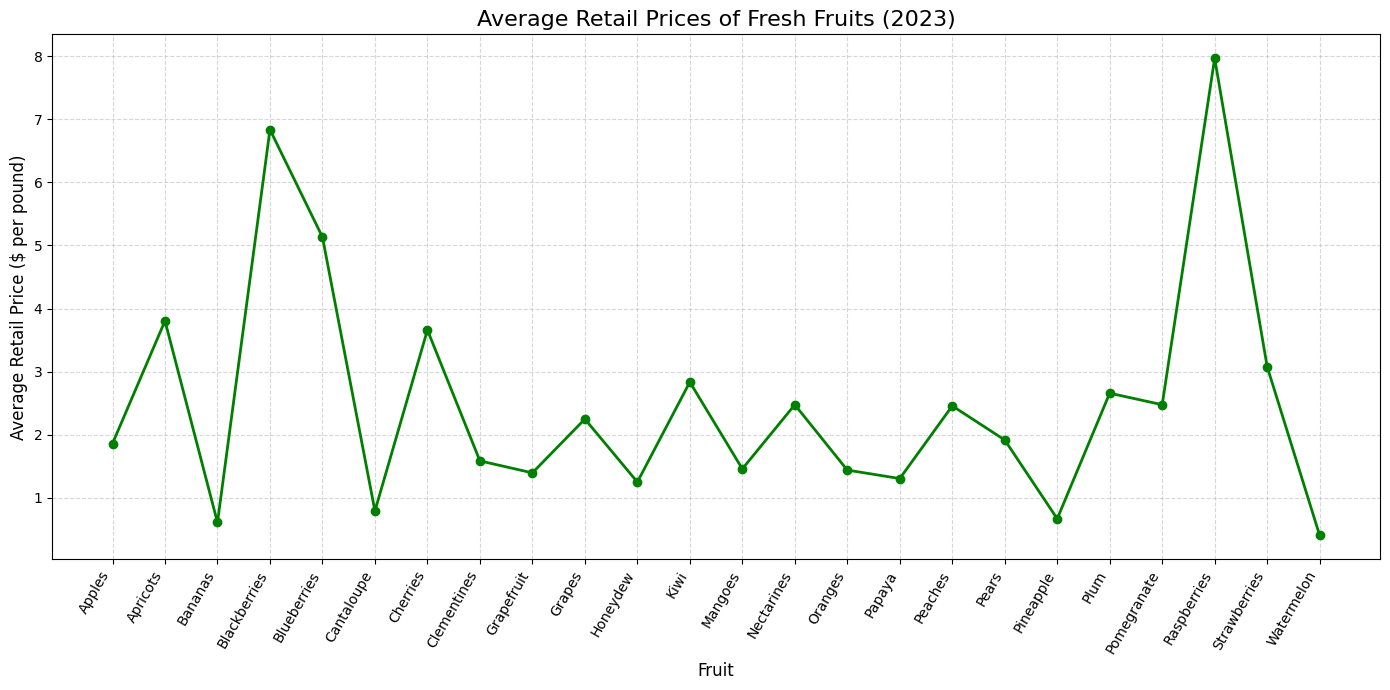

In [44]:
df = pd.read_csv(url)
fresh_fruits = df[df["Form"] == "Fresh"].copy()
fresh_fruits = fresh_fruits.sort_values("Fruit")
plt.figure(figsize=(14, 7))
plt.plot(fresh_fruits["Fruit"],fresh_fruits["AverageRetailPrice"],marker="o",linestyle="-",color="green",linewidth=2,markersize=6)
plt.title("Average Retail Prices of Fresh Fruits (2023)", fontsize=16)
plt.xlabel("Fruit", fontsize=12)
plt.ylabel("Average Retail Price ($ per pound)", fontsize=12)
plt.xticks(rotation=60, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


['Fruit', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']


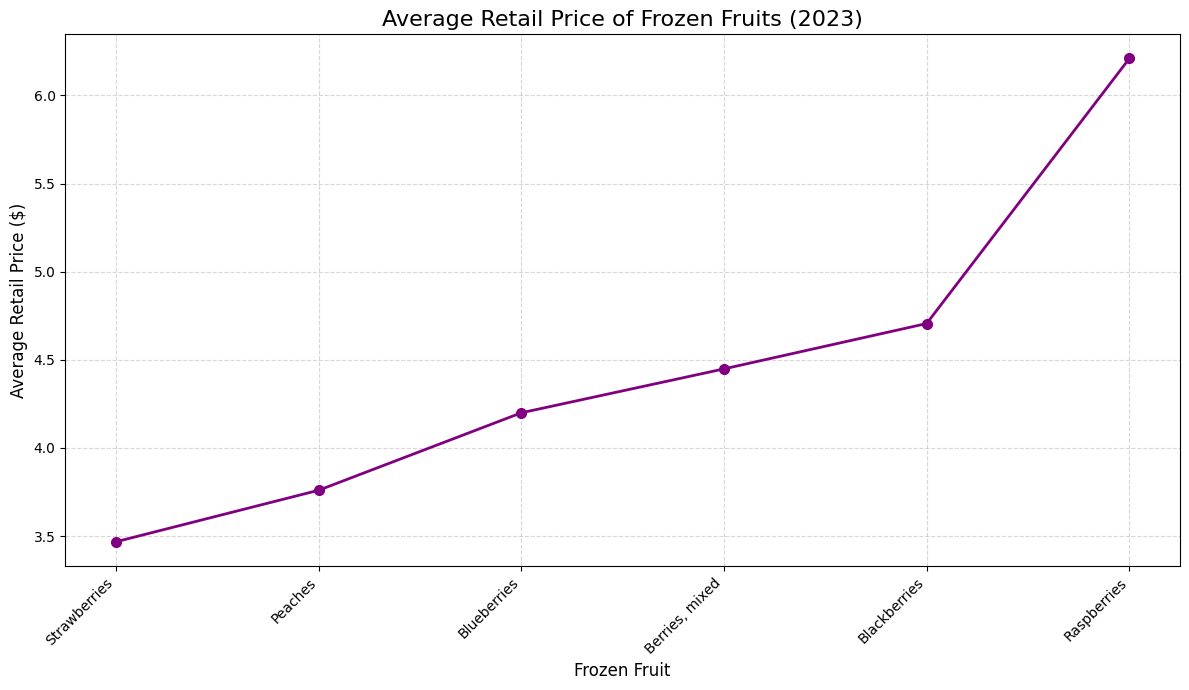

In [14]:
df = pd.read_csv(url)
print(df.columns.tolist())
fruit_column = "Fruit"
price_column = "AverageRetailPrice"
type_column = "Form"
frozen = df[df[type_column].astype(str).str.contains("frozen", case=False, na=False)].copy()
frozen[price_column] = pd.to_numeric(frozen[price_column], errors="coerce")
avg_prices = (
    frozen.groupby(fruit_column)[price_column]
    .mean()
    .dropna()
    .sort_values())
plt.figure(figsize=(12, 7))
plt.plot(avg_prices.index,avg_prices.values,marker="o",linestyle="-",color="purple",linewidth=2,markersize=7)
plt.title("Average Retail Price of Frozen Fruits (2023)", fontsize=16)
plt.xlabel("Frozen Fruit", fontsize=12)
plt.ylabel("Average Retail Price ($)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

['Fruit', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']


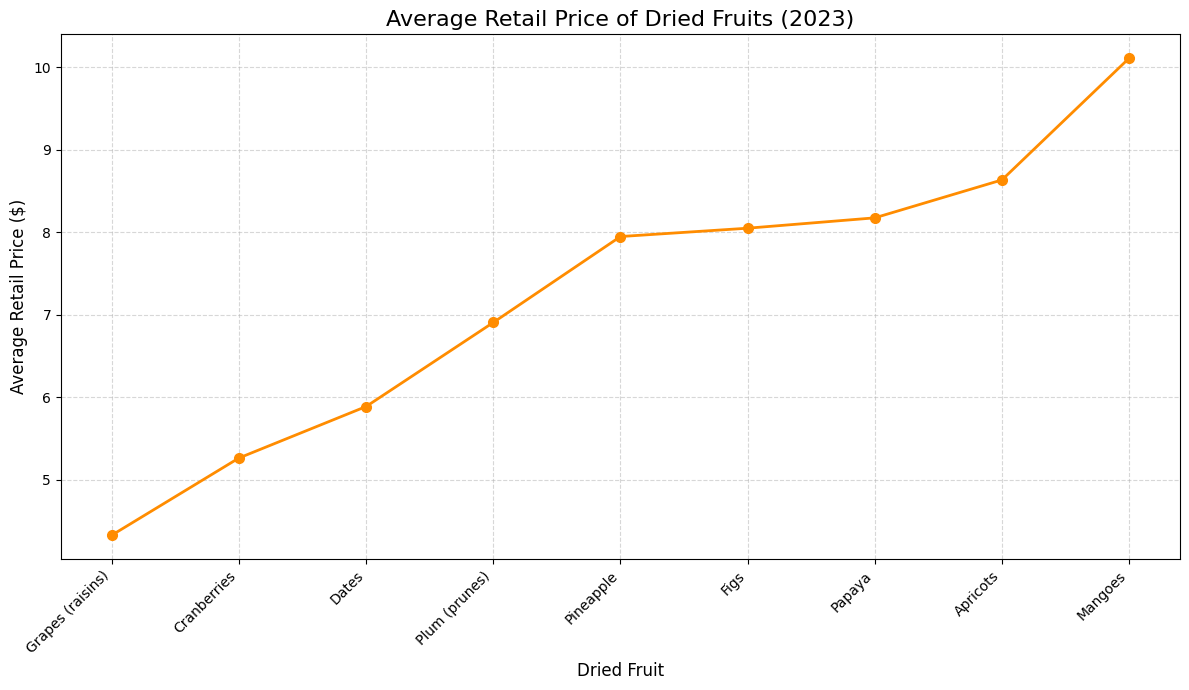

In [15]:
df = pd.read_csv(url)
print(df.columns.tolist())
fruit_column = "Fruit"
price_column = "AverageRetailPrice"
type_column = "Form"
dried = df[df[type_column].astype(str).str.contains("dried", case=False, na=False)].copy()
dried[price_column] = pd.to_numeric(dried[price_column], errors="coerce")
avg_prices = (
    dried.groupby(fruit_column)[price_column]
    .mean()
    .dropna()
    .sort_values())
plt.figure(figsize=(12, 7))
plt.plot(avg_prices.index,avg_prices.values,marker="o",linestyle="-",color="darkorange",linewidth=2,markersize=7)
plt.title("Average Retail Price of Dried Fruits (2023)", fontsize=16)
plt.xlabel("Dried Fruit", fontsize=12)
plt.ylabel("Average Retail Price ($)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

['Fruit', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']


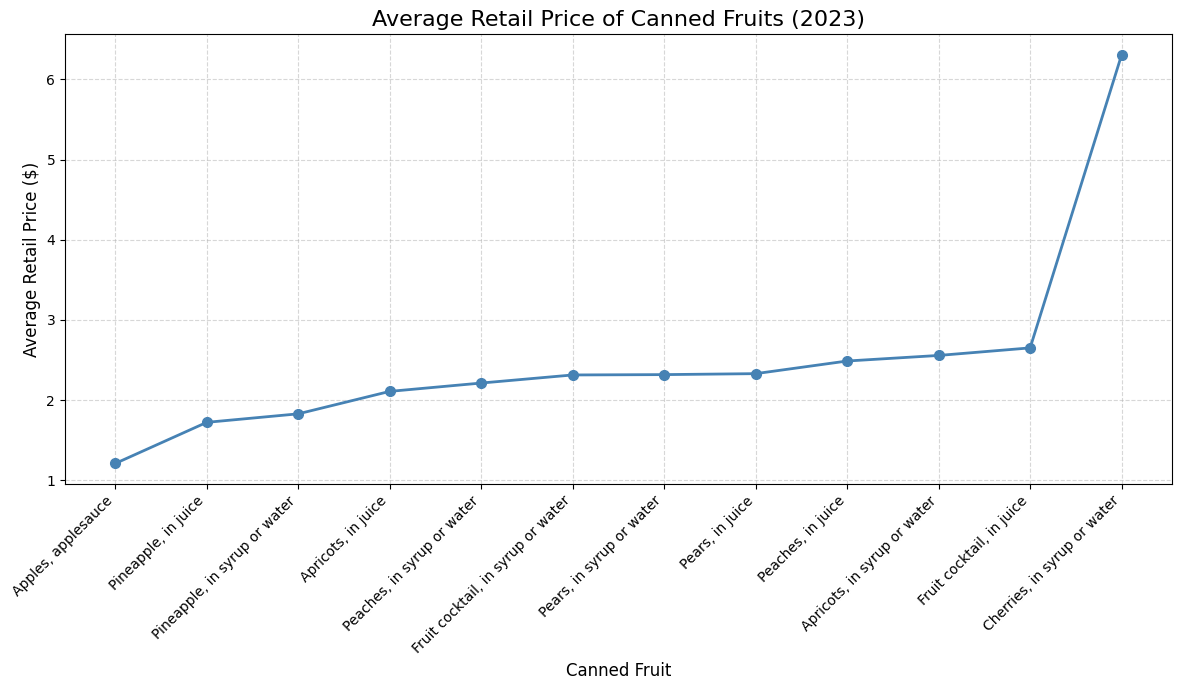

In [20]:
df = pd.read_csv(url)
print(df.columns.tolist())
fruit_column = "Fruit"
price_column = "AverageRetailPrice"
type_column = "Form"
canned = df[df[type_column].astype(str).str.contains("canned", case=False, na=False)].copy()
canned[price_column] = pd.to_numeric(canned[price_column], errors="coerce")
avg_prices = (
    canned.groupby(fruit_column)[price_column]
    .mean()
    .dropna()
    .sort_values())
plt.figure(figsize=(12, 7))
plt.plot(avg_prices.index,avg_prices.values,marker="o",linestyle="-",color="steelblue",linewidth=2,markersize=7)
plt.title("Average Retail Price of Canned Fruits (2023)", fontsize=16)
plt.xlabel("Canned Fruit", fontsize=12)
plt.ylabel("Average Retail Price ($)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

['Fruit', 'Form', 'AverageRetailPrice', 'AverageRetailPriceUnitOfMeasure', 'PreparationYieldFactor', 'SizeOfACupEquivalent ', 'CupEquivalentUnitOfMeasure', 'AveragePricePerCupEquivalent']


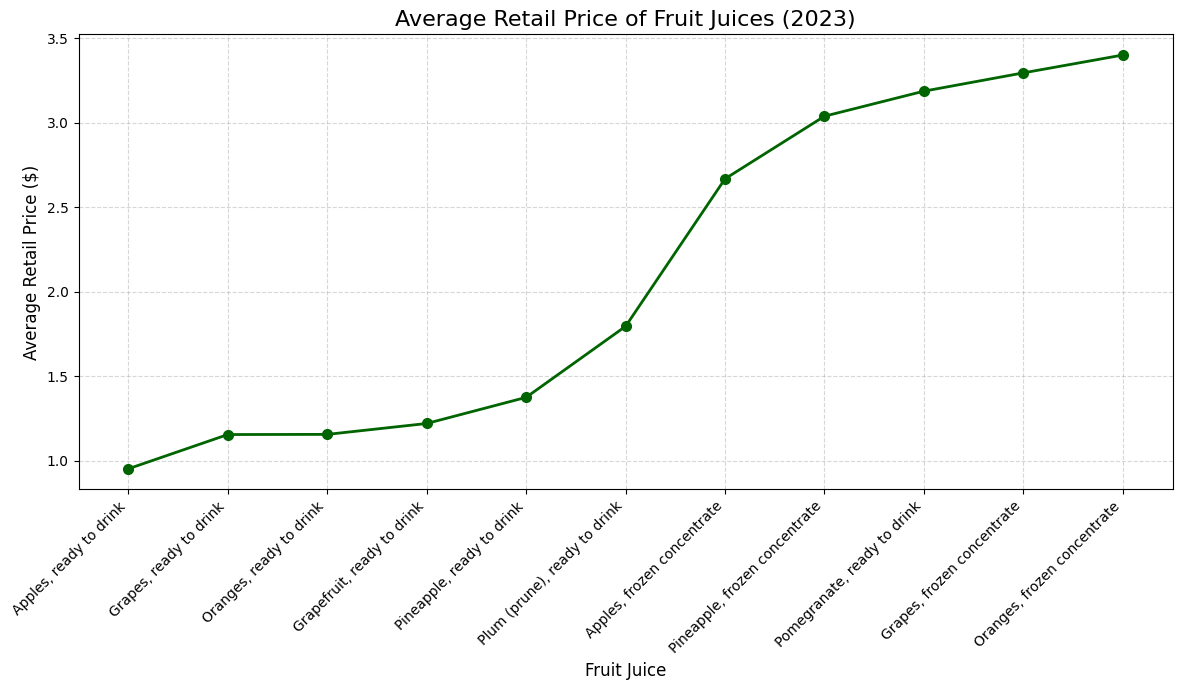

In [19]:
df = pd.read_csv(url)
print(df.columns.tolist())
fruit_column = "Fruit"
price_column = "AverageRetailPrice"
type_column = "Form"
juiced = df[df[type_column].astype(str).str.contains("juice", case=False, na=False)].copy()
juiced[price_column] = pd.to_numeric(juiced[price_column], errors="coerce")
avg_prices = (
    juiced.groupby(fruit_column)[price_column]
    .mean()
    .dropna()
    .sort_values())
plt.figure(figsize=(12, 7))
plt.plot(avg_prices.index,avg_prices.values,marker="o",linestyle="-",color="darkgreen",linewidth=2,markersize=7)
plt.title("Average Retail Price of Fruit Juices (2023)", fontsize=16)
plt.xlabel("Fruit Juice", fontsize=12)
plt.ylabel("Average Retail Price ($)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

#Average Price per Cup Equivalent by Fruit Form
This line graph and violin graph compares the average price per cup equivalent for the different fruit forms in the 2023 data set. Each point shows the average price for a single form, with categories sorted in order of increasing average price. The graph shows the average difference in costs by product forms. These averages characterize the products in the data set, and do not suggest that all products in one category are cheaper than all products in another.

In [43]:

# Count the number of products in each fruit form
print(df["Form"].value_counts(dropna=False))


Form
Fresh     24
Canned    12
Juice     11
Dried      9
Frozen     6
Name: count, dtype: int64


Average Price per Cup Equivalent by Fruit Form:
Form
Juice     0.63
Fresh     1.06
Dried     1.11
Frozen    1.48
Canned    1.55
Name: AveragePricePerCupEquivalent, dtype: float64


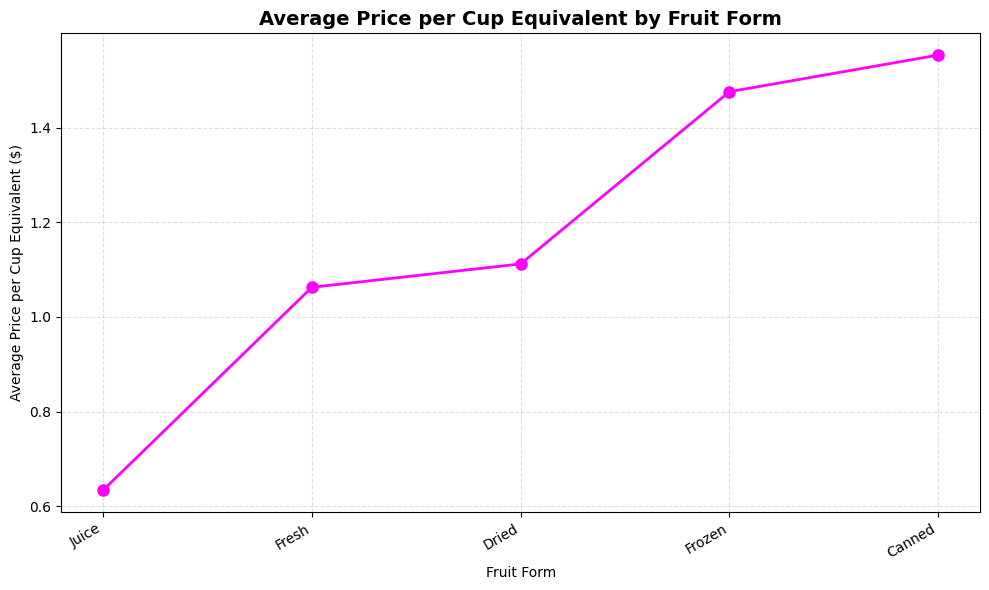

In [45]:
df = pd.read_csv(url)
price_col = "AveragePricePerCupEquivalent"
chart_data = df[["Form", price_col]].copy()
chart_data[price_col] = pd.to_numeric(
    chart_data[price_col], errors="coerce")
chart_data = chart_data.dropna(subset=["Form", price_col])
form_summary = (chart_data.groupby("Form")[price_col]
    .mean()
    .sort_values())
print("Average Price per Cup Equivalent by Fruit Form:")
print(form_summary.round(2))
plt.figure(figsize=(10, 6))
plt.plot(form_summary.index,form_summary.values,marker="o",linestyle="-",color="magenta",linewidth=2,markersize=8)
plt.title("Average Price per Cup Equivalent by Fruit Form",fontsize=14,fontweight="bold")
plt.xlabel("Fruit Form")
plt.ylabel("Average Price per Cup Equivalent ($)")
plt.xticks(rotation=30, ha="right")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


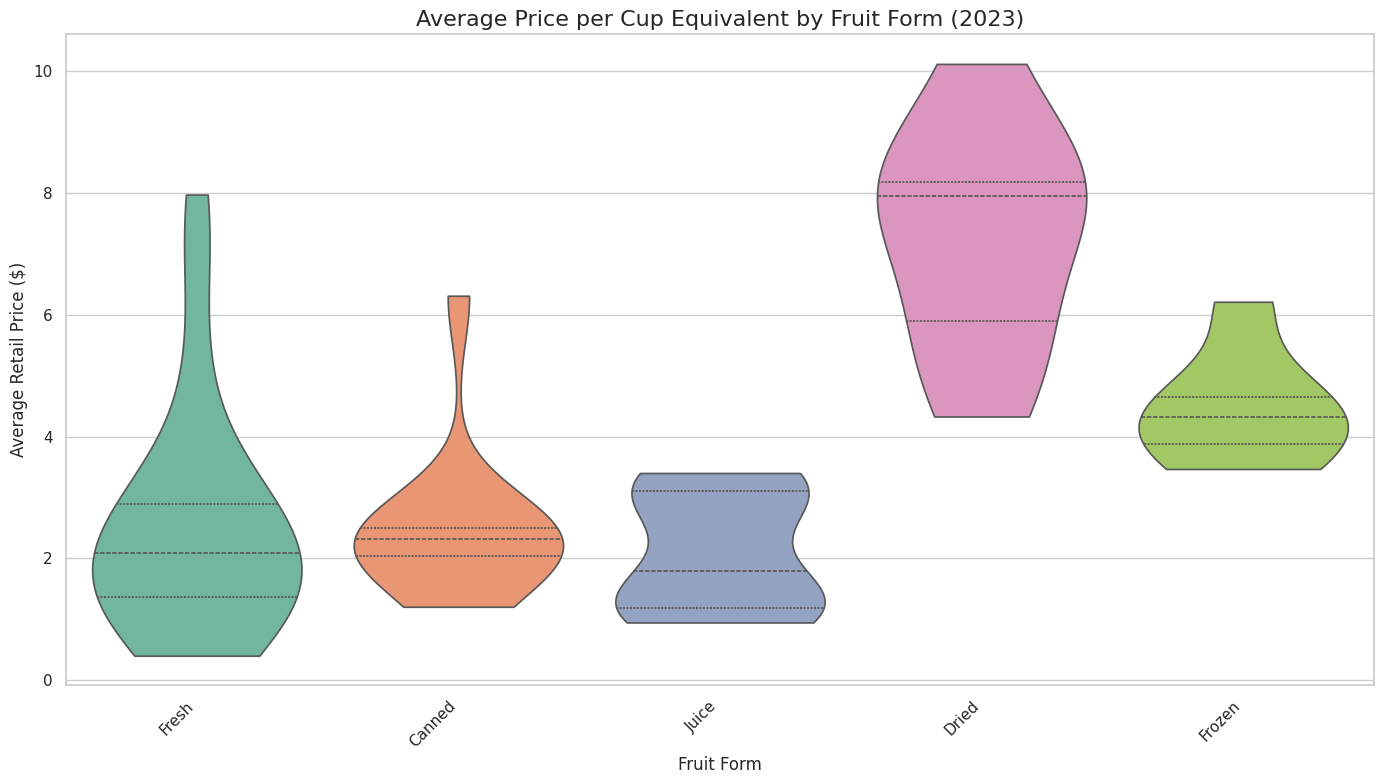

In [53]:
df = pd.read_csv(url)
df.columns = df.columns.str.strip()
df["Form"] = df["Form"].astype(str).str.strip()
df["AverageRetailPrice"] = pd.to_numeric(df["AverageRetailPrice"], errors="coerce")
df = df.dropna(subset=["Form", "AverageRetailPrice"])
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 8))
sns.violinplot(data=df,x="Form",y="AverageRetailPrice",hue="Form",palette="Set2",legend=False,inner="quartile",cut=0)
plt.title("Average Price per Cup Equivalent by Fruit Form (2023)", fontsize=16)
plt.xlabel("Fruit Form", fontsize=12)
plt.ylabel("Average Retail Price ($)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


#Which fruit products cost the most per cup equivalent?
Before getting to our point of research, it is best to ask the question of what comes before finding the lowest cost per cup equivalent. Within this bar chart we can take into account that one of the most expensive fruit product in 2023 was canned cherries with 4.3 per cup, and frozen black berries as the least expensive with a 1.5 estimate. Overall, the chart compares estimated costs using a common cup-equivalent measure, making it easier to identify relatively expensive products. These values represent average estimates rather than the prices charged by a specific grocery store.

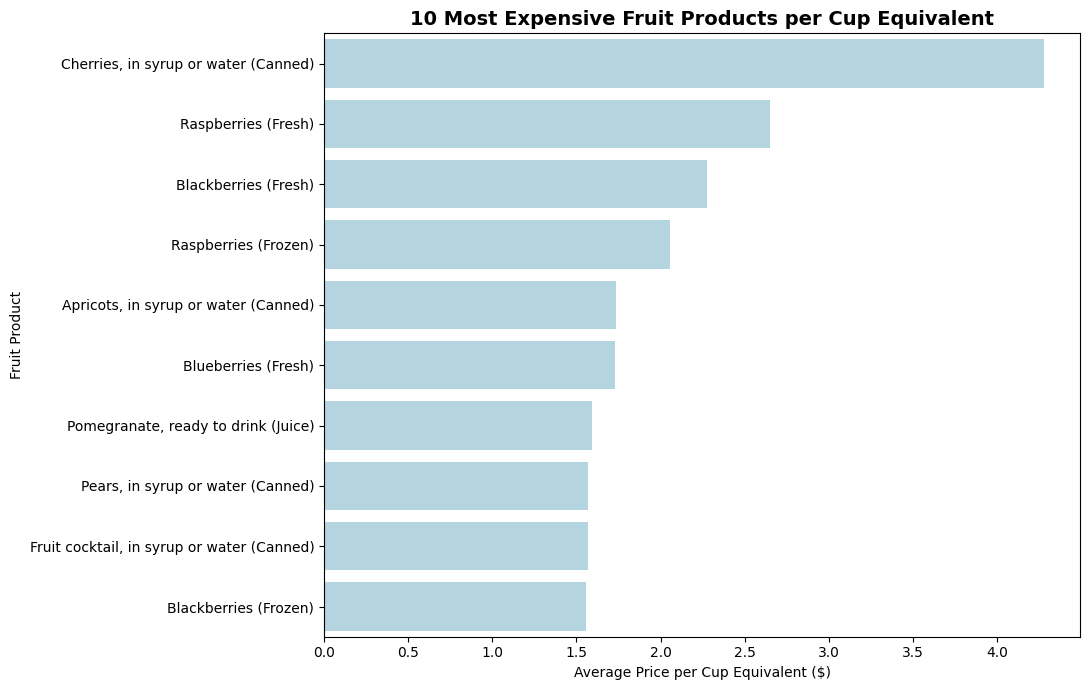

In [46]:
df = pd.read_csv(url)
price_col = "AveragePricePerCupEquivalent"
chart_data = df[["Fruit", "Form", price_col]].copy()
chart_data[price_col] = pd.to_numeric(
    chart_data[price_col], errors="coerce")
chart_data = chart_data.dropna(subset=[price_col])
most_expensive = chart_data.nlargest(10, price_col).copy()
most_expensive["Product"] = (most_expensive["Fruit"].astype(str)
    + " (" + most_expensive["Form"].astype(str) + ")")
plt.figure(figsize=(11, 7))
sns.barplot(data=most_expensive, x=price_col, y="Product", color="lightblue")
plt.title("10 Most Expensive Fruit Products per Cup Equivalent",fontsize=14,fontweight="bold")
plt.xlabel("Average Price per Cup Equivalent ($)")
plt.ylabel("Fruit Product")
plt.tight_layout()
plt.show()


# Which fruit products offer the lowest cost per cup equivalent?
Within this bar graph, it is comparing the ten fruit product records with the lowest average price per cup equivalent in the 2023 dataset. The horizontal bars show the estimated cost of one cup equivalent for each product. The chart helps identify relatively inexpensive options using a common measurement. Additionally, we can determine within this data that lowest priced per cup is fresh watermelon. Considerably, it could be due to watermelons overall size being distibuted into premeasured cups for sale.

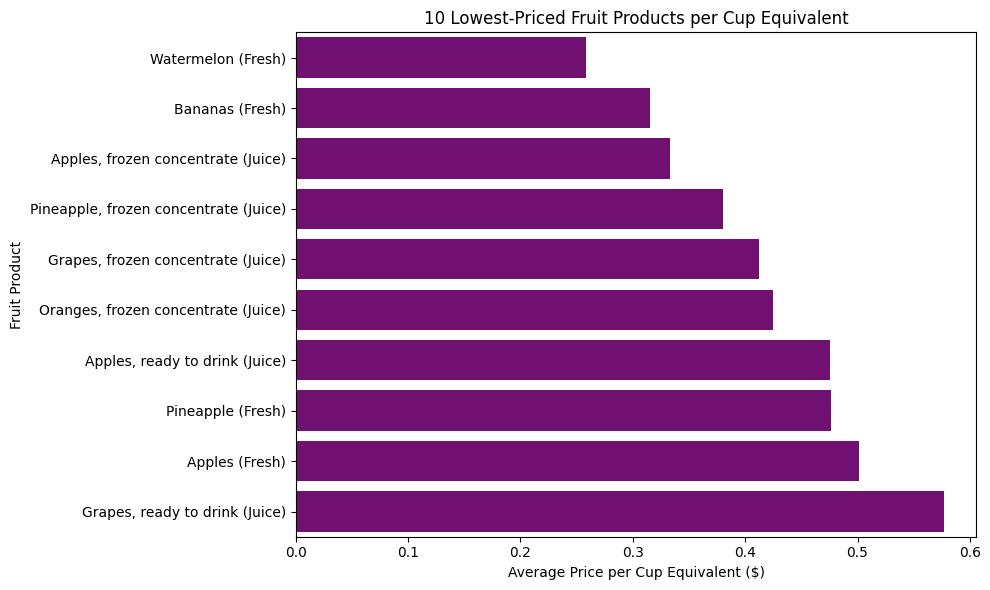

In [47]:
if "df" not in globals():
    df = pd.read_csv(url)
price_col = "AveragePricePerCupEquivalent"
chart_data = df[["Fruit", "Form", price_col]].copy()
chart_data[price_col] = pd.to_numeric(chart_data[price_col], errors="coerce")
chart_data = chart_data.dropna(subset=[price_col])
cheapest = chart_data.nsmallest(10, price_col).copy()
cheapest["Product"] = (cheapest["Fruit"].astype(str)
    + " (" + cheapest["Form"].astype(str) + ")")
plt.figure(figsize=(10, 6))
sns.barplot(data=cheapest, x=price_col, y="Product", color="purple")

plt.title("10 Lowest-Priced Fruit Products per Cup Equivalent")
plt.xlabel("Average Price per Cup Equivalent ($)")
plt.ylabel("Fruit Product")
plt.tight_layout()
plt.show()


#Distribution of Average Fruit Prices per Cup Equivalent

The histogram shows the distribution of average prices per cup equivalent for the fruit products in the dataset. The bars show the number of products in each price range. The mean and median reference lines allow you to compare the overall average to the middle price. This visual helps to determine the common price ranges and if the distribution is impacted by relatively expensive products.

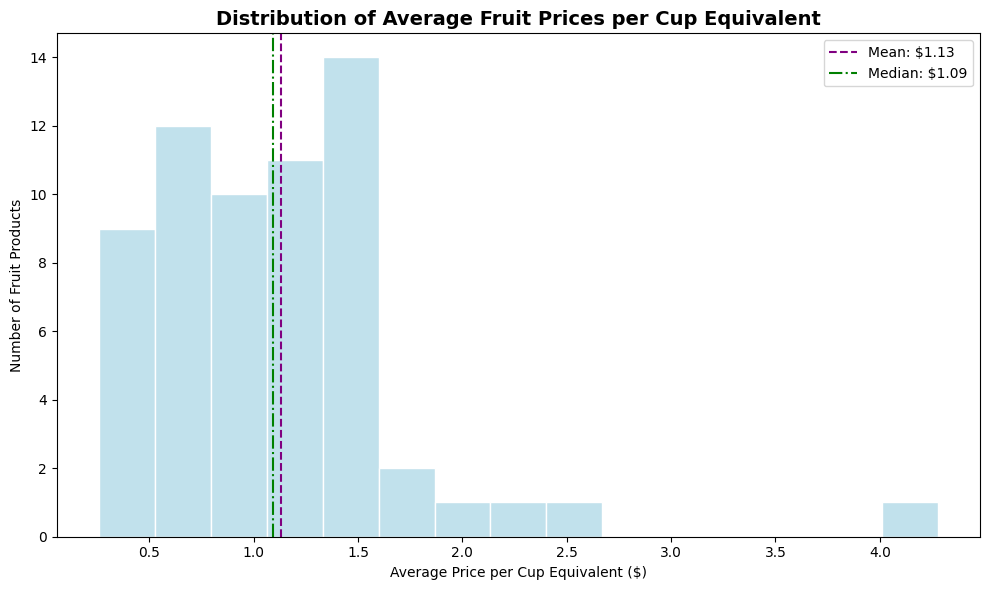

Number of products analyzed: 62
Mean price per cup equivalent: $1.13
Median price per cup equivalent: $1.09


In [48]:
df = pd.read_csv(url)
price_col = "AveragePricePerCupEquivalent"
prices = pd.to_numeric(df[price_col], errors="coerce").dropna()
mean_price = prices.mean()
median_price = prices.median()
plt.figure(figsize=(10, 6))
sns.histplot(prices,bins=15,color="lightblue",edgecolor="white")
plt.axvline(mean_price, color="purple", linestyle="--", label=f"Mean: ${mean_price:.2f}")
plt.axvline(median_price, color="green", linestyle="-.", label=f"Median: ${median_price:.2f}")
plt.title("Distribution of Average Fruit Prices per Cup Equivalent",fontsize=14,fontweight="bold")
plt.xlabel("Average Price per Cup Equivalent ($)")
plt.ylabel("Number of Fruit Products")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Number of products analyzed: {len(prices)}")
print(f"Mean price per cup equivalent: ${mean_price:.2f}")
print(f"Median price per cup equivalent: ${median_price:.2f}")


#Fruit Price Analysis 2023: A Visualization of Data Project

This project analyzed the 2023 fruit price dataset, focusing on cup-equivalent prices, distribution, and differences across fruit forms. Visualizations compared price ranges from least to most expensive, highlighting how data visualization aids in understanding price comparisons. Limitations include the dataset's average prices, which may not reflect current grocery prices. Overall, it showcased how Python and data visualization reveal patterns in fruit prices and communicate findings effectively.